# Optiver at the close
**Frame:** Predicting stock 60s move relative to market at the close for the auction at 16:00.

**The data:**
- **200** stocks, **481** days, **10** minutes in group of **10** seconds
- Continuous order book: bid and ask price and size, and wap (weighted average price)
- Auction book: orders at the close, and imbalances

**Intuition**: More shares to buy than sell the price should go up to encourage sellers.

**METRIC**: MAE

**Traps:**
- future information use
- non independent rows
- cleaning with hindsight
- extreme values

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import sklearn as sk
import lightgbm as lgb
from pprint import pp

# **Data Summary**

In [2]:
raw = pd.read_csv("./optiver-trading-at-the-close/train.csv")
print(raw.shape)
display(raw.head())

(5237980, 17)


,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id,row_id
0,0,0,0,3180602.69,1,0.999812,13380276.64,NaN,NaN,0.999812,60651.50,1.000026,8493.03,1.0,-3.029704,0,0_0_0
1,1,0,0,166603.91,-1,0.999896,1642214.25,NaN,NaN,0.999896,3233.04,1.000660,20605.09,1.0,-5.519986,0,0_0_1
2,2,0,0,302879.87,-1,0.999561,1819368.03,NaN,NaN,0.999403,37956.00,1.000298,18995.00,1.0,-8.389950,0,0_0_2
3,3,0,0,11917682.27,-1,1.000171,18389745.62,NaN,NaN,0.999999,2324.90,1.000214,479032.40,1.0,-4.010200,0,0_0_3
4,4,0,0,447549.96,-1,0.999532,17860614.95,NaN,NaN,0.999394,16485.54,1.000016,434.10,1.0,-7.349849,0,0_0_4


In [3]:
display(raw.agg(["min","max"]))

,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id,row_id
min,0,0,0,0.000000e+00,-1,0.935285,4.316610e+03,0.000077,0.786988,0.934915,0.0,0.939827,0.0,0.938008,-385.28980,0,0_0_0
max,199,480,540,2.982028e+09,1,1.077488,7.713682e+09,437.953100,1.309732,1.077488,30287840.0,1.077836,54405000.0,1.077675,446.07043,26454,9_90_99


In [4]:
display(raw.describe())

,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id
count,5.237980e+06,5.237980e+06,5.237980e+06,5.237760e+06,5.237980e+06,5.237760e+06,5.237760e+06,2.343638e+06,2.380800e+06,5.237760e+06,5.237980e+06,5.237760e+06,5.237980e+06,5.237760e+06,5.237892e+06,5.237980e+06
mean,9.928856e+01,2.415100e+02,2.700000e+02,5.715293e+06,-1.189619e-02,9.999955e-01,4.510025e+07,1.001713e+00,9.996601e-01,9.997263e-01,5.181359e+04,1.000264e+00,5.357568e+04,9.999920e-01,-4.756125e-02,1.331005e+04
std,5.787176e+01,1.385319e+02,1.587451e+02,2.051591e+07,8.853374e-01,2.532497e-03,1.398413e+08,7.214705e-01,1.216920e-02,2.499345e-03,1.114214e+05,2.510042e-03,1.293554e+05,2.497509e-03,9.452860e+00,7.619271e+03
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,9.352850e-01,4.316610e+03,7.700000e-05,7.869880e-01,9.349150e-01,0.000000e+00,9.398270e-01,0.000000e+00,9.380080e-01,-3.852898e+02,0.000000e+00
25%,4.900000e+01,1.220000e+02,1.300000e+02,8.453415e+04,-1.000000e+00,9.987630e-01,5.279575e+06,9.963320e-01,9.971000e-01,9.985290e-01,7.374720e+03,9.990290e-01,7.823700e+03,9.987810e-01,-4.559755e+00,6.729000e+03
50%,9.900000e+01,2.420000e+02,2.700000e+02,1.113604e+06,0.000000e+00,9.999670e-01,1.288264e+07,9.998830e-01,9.998890e-01,9.997280e-01,2.196900e+04,1.000207e+00,2.301792e+04,9.999970e-01,-6.020069e-02,1.334500e+04
75%,1.490000e+02,3.610000e+02,4.100000e+02,4.190951e+06,1.000000e+00,1.001174e+00,3.270013e+07,1.003318e+00,1.002590e+00,1.000905e+00,5.583168e+04,1.001414e+00,5.787841e+04,1.001149e+00,4.409552e+00,1.990700e+04
max,1.990000e+02,4.800000e+02,5.400000e+02,2.982028e+09,1.000000e+00,1.077488e+00,7.713682e+09,4.379531e+02,1.309732e+00,1.077488e+00,3.028784e+07,1.077836e+00,5.440500e+07,1.077675e+00,4.460704e+02,2.645400e+04


In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5237980 entries, 0 to 5237979
Data columns (total 17 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   stock_id                 int64  
 1   date_id                  int64  
 2   seconds_in_bucket        int64  
 3   imbalance_size           float64
 4   imbalance_buy_sell_flag  int64  
 5   reference_price          float64
 6   matched_size             float64
 7   far_price                float64
 8   near_price               float64
 9   bid_price                float64
 10  bid_size                 float64
 11  ask_price                float64
 12  ask_size                 float64
 13  wap                      float64
 14  target                   float64
 15  time_id                  int64  
 16  row_id                   str    
dtypes: float64(11), int64(5), str(1)
memory usage: 679.4 MB


In [6]:
display(raw.head(2))

,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id,row_id
0,0,0,0,3180602.69,1,0.999812,13380276.64,NaN,NaN,0.999812,60651.50,1.000026,8493.03,1.0,-3.029704,0,0_0_0
1,1,0,0,166603.91,-1,0.999896,1642214.25,NaN,NaN,0.999896,3233.04,1.000660,20605.09,1.0,-5.519986,0,0_0_1


In [7]:
display(raw.tail(2))

,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id,row_id
5237978,198,480,540,1000898.84,1,0.999210,94773271.05,0.999210,0.999210,0.998970,125631.72,0.999210,669893.00,0.999008,-1.540184,26454,480_540_198
5237979,199,480,540,1884285.71,-1,1.002129,24073677.32,1.000859,1.001494,1.002129,250081.44,1.002447,300167.56,1.002274,-6.530285,26454,480_540_199


In [8]:
display(raw.sample(2))

,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id,row_id
4301842,62,395,490,0.00,0,0.996319,7514637.90,0.996319,0.996319,0.995924,22920.3,0.996376,37747.46,0.996095,5.689859,21774,395_490_62
1625252,130,151,270,1979344.01,1,0.998396,54240553.87,NaN,NaN,0.998054,8757.0,0.998168,1488.86,0.998151,-5.080104,8332,151_270_130


# **Indexing the data with** `time_id`

In [9]:
seconds_groups = raw["seconds_in_bucket"].unique()
pp(seconds_groups)
pp(raw.date_id.nunique())
pp(raw.time_id.nunique())
pp(raw.stock_id.nunique())

array([  0,  10,  20,  30,  40,  50,  60,  70,  80,  90, 100, 110, 120,
       130, 140, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250,
       260, 270, 280, 290, 300, 310, 320, 330, 340, 350, 360, 370, 380,
       390, 400, 410, 420, 430, 440, 450, 460, 470, 480, 490, 500, 510,
       520, 530, 540])
481
26455
200


In [10]:
assert(481*55 == 26455) # No data missing /day+seconds pair
pp(26455*200-len(raw)) # Missing data per stock

53020


In [11]:
pp(raw.isna().sum())

stock_id                         0
date_id                          0
seconds_in_bucket                0
imbalance_size                 220
imbalance_buy_sell_flag          0
reference_price                220
matched_size                   220
far_price                  2894342
near_price                 2857180
bid_price                      220
bid_size                         0
ask_price                      220
ask_size                         0
wap                            220
target                          88
time_id                          0
row_id                           0
dtype: int64


In [12]:
raw.isna().groupby(raw.seconds_in_bucket).sum()

,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id,row_id
seconds_in_bucket,,,,,,,,,,,,,,,,,
0,0,0,0,4,0,4,4,95236,95236,4,0,4,0,4,4,0,0
10,0,0,0,4,0,4,4,95236,95236,4,0,4,0,4,2,0,0
20,0,0,0,4,0,4,4,95236,95236,4,0,4,0,4,2,0,0
30,0,0,0,4,0,4,4,95236,95236,4,0,4,0,4,2,0,0
40,0,0,0,4,0,4,4,95236,95236,4,0,4,0,4,2,0,0
50,0,0,0,4,0,4,4,95236,95236,4,0,4,0,4,2,0,0
60,0,0,0,4,0,4,4,95236,95236,4,0,4,0,4,2,0,0
70,0,0,0,4,0,4,4,95236,95236,4,0,4,0,4,2,0,0
80,0,0,0,4,0,4,4,95236,95236,4,0,4,0,4,2,0,0


<Axes: xlabel='seconds_in_bucket', ylabel='mean |price - 1|'>

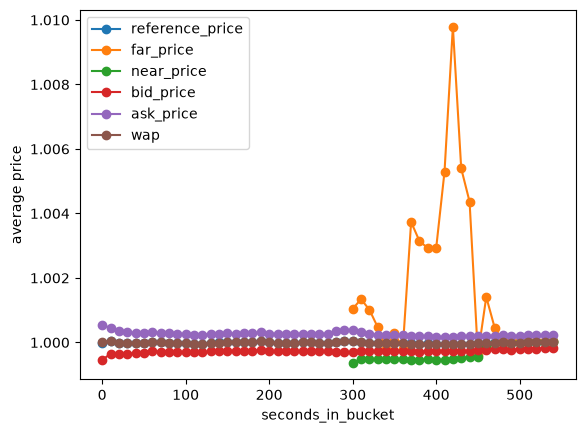

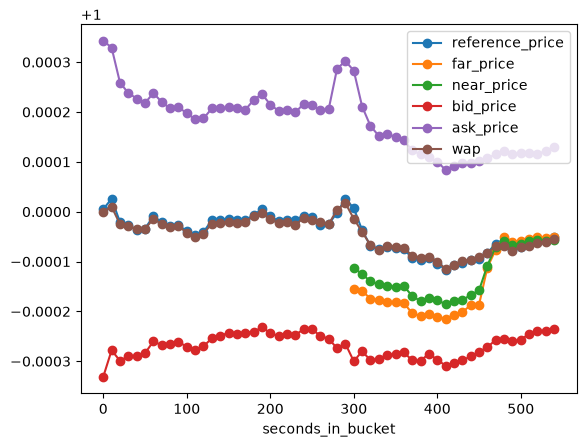

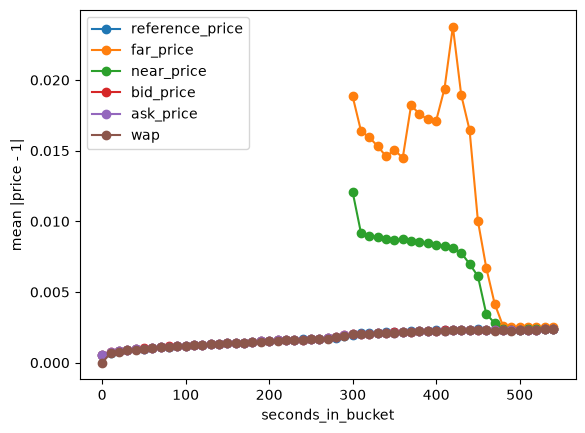

In [13]:
columns = ["reference_price", "far_price", "near_price", "bid_price", "ask_price", "wap"]

avg_path = raw.groupby("seconds_in_bucket")[columns].mean()
avg_path.plot(marker="o", xlabel="seconds_in_bucket", ylabel="average price")
raw.groupby("seconds_in_bucket")[columns].median().plot(marker="o")
dev = (raw[columns] - 1).abs()
dev.groupby(raw["seconds_in_bucket"]).mean().plot(marker="o", ylabel="mean |price - 1|")

## The case of `far_price`

In [14]:
pp((raw.far_price<0.7).sum())
pp((raw.far_price>1.3).sum())

np.int64(99)
np.int64(241)


<Axes: >

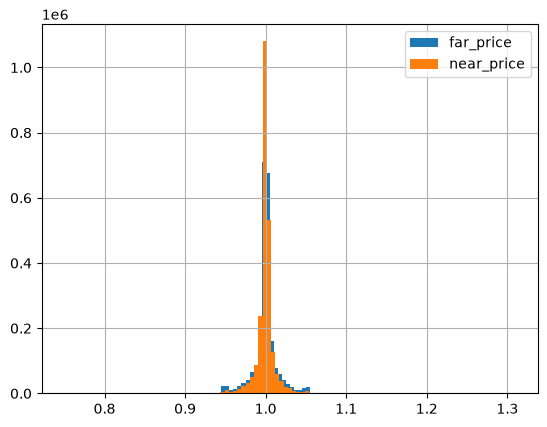

In [15]:
raw.far_price.clip(0.75,1.25).hist(bins=100, legend=True)
raw.near_price.hist(bins=100, legend=True)

## 220 missing values: are they in common ?

In [16]:
columns = ["imbalance_size", "reference_price", "matched_size", "ask_price", "bid_price", "wap", "target"]
mask = raw["imbalance_size"].isna()
print(raw[columns][mask].isna().sum())

imbalance_size     220
reference_price    220
matched_size       220
ask_price          220
bid_price          220
wap                220
target              88
dtype: int64


## 88 missing targets not 220

In [17]:
mask = ~raw.target.isna() & raw.ask_price.isna()
raw[mask].head()

,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id,row_id
375268,131,35,300,NaN,0,NaN,NaN,NaN,NaN,NaN,75210.5,NaN,33462.0,NaN,90.130570,1955,35_300_131
375460,131,35,310,NaN,0,NaN,NaN,NaN,NaN,NaN,75210.5,NaN,39468.0,NaN,3.499985,1956,35_310_131
375652,131,35,320,NaN,0,NaN,NaN,NaN,NaN,NaN,75210.5,NaN,39468.0,NaN,1.239777,1957,35_320_131
375844,131,35,330,NaN,0,NaN,NaN,NaN,NaN,NaN,75210.5,NaN,39468.0,NaN,0.979900,1958,35_330_131
376036,131,35,340,NaN,0,NaN,NaN,NaN,NaN,NaN,75210.5,NaN,39468.0,NaN,-0.050068,1959,35_340_131


# **Cleaning the dataframe**

- clip far_price values to 0.75 , 1.25
- drop nans values in prices, thus also in target
- drop 220 value of targets because we have no data to predict, 88 missing + 132 no data

In [18]:
df = raw.copy()
df.far_price = df.far_price.clip(0.75,1.25)
df = df[~df.ask_price.isna()]

# **What is the `target` like ?**

In [19]:
target = df.target
summ_target = dict(mean = target.mean(), vol = target.std(), mini = target.min(), maxi = target.max(), q1th = target.quantile(0.1), q50th = target.quantile(0.5), q99th = target.quantile(0.99), kurt = target.kurtosis(), skew = target.skew())
pp(summ_target)

{'mean': np.float64(-0.047588860833626775),
 'vol': np.float64(9.452816364260977),
 'mini': np.float64(-385.2898),
 'maxi': np.float64(446.07043),
 'q1th': np.float64(-9.829998),
 'q50th': np.float64(-0.06020069),
 'q99th': np.float64(25.99001),
 'kurt': np.float64(22.557462326417326),
 'skew': np.float64(0.20451374209786918)}


<Axes: >

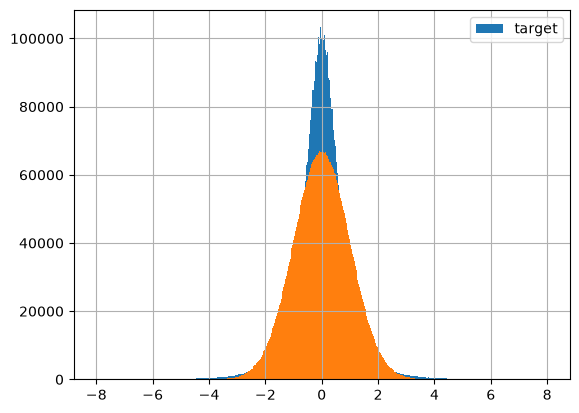

In [20]:
n_target = (target - target.mean())/target.std()
n_rand = pd.Series(np.random.randn(len(target)))
n_target.hist(bins=np.linspace(-8,8,500), legend=True)
n_rand.hist(bins=np.linspace(-8,8,500), legend=True)

## Target has fat tails, impact on OLS: the extreme values will pull the metric, different objective than MAE

<Axes: xlabel='seconds_in_bucket'>

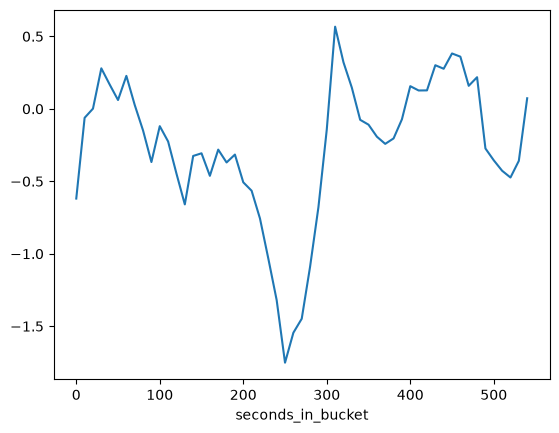

In [21]:
target_evol = df[df.stock_id==0].groupby("seconds_in_bucket")["target"].mean()
target_evol.plot()

In [22]:
target_per_stock = df.groupby("stock_id")["target"]
range_tps = (target_per_stock.max() - target_per_stock.min()).sort_values()
vol_tps = target_per_stock.std().sort_values()
print(range_tps.head(), range_tps.tail())
print(vol_tps.head(), vol_tps.tail())

stock_id
105    69.170593
55     69.760084
175    74.260235
160    81.009863
4      81.029537
Name: target, dtype: float64 stock_id
56     505.76031
174    510.36002
142    596.55965
31     608.68919
5      659.66963
Name: target, dtype: float64
stock_id
112    4.827514
45     4.848838
130    4.997084
160    5.193113
55     5.219140
Name: target, dtype: float64 stock_id
174    17.778500
92     17.907262
86     17.981217
31     20.202133
82     22.004510
Name: target, dtype: float64


<Axes: xlabel='lag (snapshots of 10 s)', ylabel='autocorrelation'>

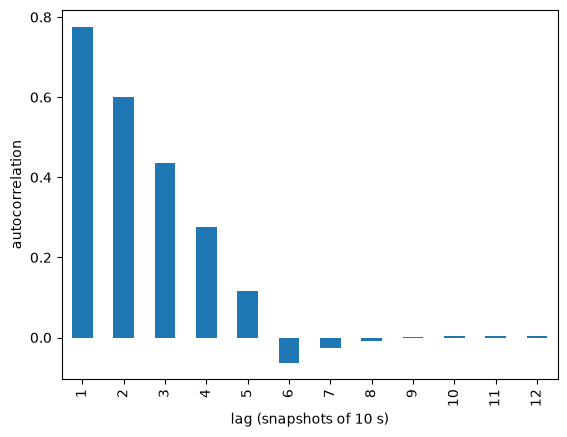

In [23]:
df = df.sort_values(["stock_id", "time_id"])
g = df.groupby(["stock_id", "date_id"])["target"]

acf = pd.Series({k: df["target"].corr(g.shift(k)) for k in range(1, 13)})
acf.plot(kind="bar", xlabel="lag (snapshots of 10 s)", ylabel="autocorrelation")

In [24]:
n = 55
lags = acf.index
n_eff = n / (1 + 2 * ((1 - lags / n) * acf).sum())
print(n_eff)

10.83146923528215


## Protocol

**Prediction moment.** A prediction for stock s at snapshot t (one `time_id`) is made at t.

**Known at time t.**
- Every column of every stock at snapshot t (all stocks are published at the same moment)
- Every earlier snapshot of the same day, for every stock
- Earlier days in full.

**Forbidden.**
- `target`, and anything built from `wap` or any price after t
- Any statistic computed on validation or test rows these are computed on train only
- Any fill of a missing value that uses a later row

**Independent unit: the day.**
- Over time: consecutive targets of a stock share 50 of their 60 seconds, so the autocorrelation at lag 1 is .8 and n_eff per stock-day is about 11 instead of 55.

**Split.** By whole days, in time order, never shuffled.
- Train: days 0–389.
- Validation: days 390–434, used to compare models and tune.
- Test: days 435–480, opened once at the very end.

**Metrics.**
- MAE on validation
- Daily IC: correlation across stocks, averaged per day. mean, std, t-stat over days and share of positive days

In [25]:
def split_by_date(df, train_end=389, val_end=434):
    train = df[df["date_id"] <= train_end]
    val   = df[(df["date_id"] > train_end) & (df["date_id"] <= val_end)]
    test  = df[df["date_id"] > val_end]
    assert len(train) + len(val) + len(test) == len(df)
    assert train["date_id"].max() < val["date_id"].min() <= val["date_id"].max() < test["date_id"].min()  # in time order, no overlap
    return train, val, test

train, val, _test = split_by_date(df)

def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

def daily_ic(df, pred_col, target_col):
    pred = df.pivot(index="time_id", columns="stock_id", values=pred_col)
    target = df.pivot(index="time_id", columns="stock_id", values=target_col)
    ic = target.corrwith(pred, axis=1)
    ic_per_day = ic.groupby(ic.index // 55).mean().dropna()
    n = len(ic_per_day)
    mean = ic_per_day.mean()
    std = ic_per_day.std()
    tstat = mean/std*np.sqrt(n)
    share = (ic_per_day>0).mean()
    return dict(mean=mean, vol=std, t=tstat, share=share)

def evaluate(df, pred, target):
    d = daily_ic(df, pred, target)
    d["mae"] = mae(df[pred], df[target])
    return d

# Sanity checks: a perfect predictor, its opposite, and a constant (IC undefined)
with np.errstate(divide="ignore", invalid="ignore"):
    print(evaluate(train, "target", "target"))
    tmp = train[["time_id", "stock_id", "target"]].assign(pred=-train["target"])
    print(evaluate(tmp, "pred", "target"))
    tmp = train[["time_id", "stock_id", "target"]].assign(pred=0)
    print(evaluate(tmp, "pred", "target"))

{'mean': np.float64(1.0), 'vol': np.float64(0.0), 't': np.float64(inf), 'share': np.float64(1.0), 'mae': np.float64(0.0)}


{'mean': np.float64(-1.0), 'vol': np.float64(0.0), 't': np.float64(-inf), 'share': np.float64(0.0), 'mae': np.float64(12.99358508370241)}


{'mean': nan, 'vol': nan, 't': np.float64(nan), 'share': nan, 'mae': np.float64(6.496792541851205)}


In [26]:
results = []

def log_results(pred, name):
    d_train = evaluate(train, pred, "target")
    d_val = evaluate(val, pred, "target")
    row = {"name": name}
    row.update({f"train_{k}": v for k, v in d_train.items()})
    row.update({f"val_{k}": v for k, v in d_val.items()})
    results.append(row)

train = train.assign(t_zeros=0)
train = train.assign(t_median=train.target.median())
val = val.assign(t_zeros=0)
val = val.assign(t_median=train.target.median())

log_results("t_zeros", "Constant zero")
log_results("t_median", "Constant median")
pp(results)

[{'name': 'Constant zero',
  'train_mean': nan,
  'train_vol': nan,
  'train_t': np.float64(nan),
  'train_share': nan,
  'train_mae': np.float64(6.496792541851205),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100963085430054)},
 {'name': 'Constant median',
  'train_mean': np.float64(1.2350263058163118e-18),
  'train_vol': np.float64(2.3740233735299764e-18),
  'train_t': np.float64(2.2071277448830675),
  'train_share': np.float64(0.6111111111111112),
  'train_mae': np.float64(6.496512608240876),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100917272940325)}]


## **H1**: imbalance drives the price movement

In [27]:
pp(train.groupby("imbalance_buy_sell_flag")["target"].agg(["mean", "std"]))

                             mean       std
imbalance_buy_sell_flag                    
-1                      -0.225349  9.389252
 0                      -0.068003  9.208483
 1                       0.140013  9.928298


In [28]:
t_flag_day = train.groupby(["date_id", "imbalance_buy_sell_flag"])["target"].mean().unstack()
pp(t_flag_day)

imbalance_buy_sell_flag        -1         0         1
date_id                                              
0                       -1.012710 -0.331460 -0.303338
1                       -0.515931 -0.815919  0.142731
2                       -0.575193 -0.495726  0.401783
3                       -0.152537 -0.153899  0.120549
4                       -0.393121  0.308387 -0.154249
...                           ...       ...       ...
385                     -0.544501 -0.152465 -0.042892
386                     -0.392897 -1.350695 -0.040020
387                      0.717896  0.124798  0.350441
388                     -0.541019 -0.261850 -0.186923
389                      0.091995 -0.019558 -0.562885

[390 rows x 3 columns]


In [29]:
print(t_flag_day.mean(), t_flag_day.std(), t_flag_day.count())

imbalance_buy_sell_flag
-1   -0.249572
 0   -0.078654
 1    0.173467
dtype: float64 imbalance_buy_sell_flag
-1    0.522568
 0    0.565755
 1    0.539401
dtype: float64 imbalance_buy_sell_flag
-1    390
 0    390
 1    390
dtype: int64


In [30]:
diff = t_flag_day[1]-t_flag_day[-1]
print(diff.mean(), diff.std(), diff.mean()/diff.std() *np.sqrt(390))

0.4230389777492497 0.6468416661393511 12.915603393522545


In [31]:
pressure = train.imbalance_buy_sell_flag * train.imbalance_size / train.matched_size

In [32]:
tmp = train.assign(pressure=pressure)
pp(evaluate(tmp, "pressure", "target"))

{'mean': np.float64(0.03094712162768737),
 'vol': np.float64(0.03537486730759659),
 't': np.float64(17.276578818129483),
 'share': np.float64(0.8179487179487179),
 'mae': np.float64(6.511210377120736)}


<Axes: xlabel='pressure'>

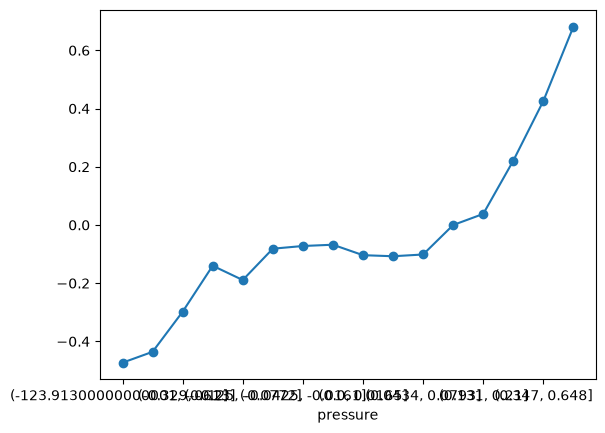

In [33]:
tmp.groupby(pd.qcut(tmp["pressure"], 20, duplicates="drop"))["target"].mean().plot(marker="o")

In [34]:
pp(evaluate(tmp[tmp.date_id<194], "pressure", "target"))
pp(evaluate(tmp[tmp.date_id>=194], "pressure", "target"))
pp(evaluate(tmp[tmp.seconds_in_bucket<300], "pressure", "target"))
pp(evaluate(tmp[tmp.seconds_in_bucket>=300], "pressure", "target"))

{'mean': np.float64(0.03099851481640359),
 'vol': np.float64(0.033692668712320246),
 't': np.float64(12.814637928073488),
 'share': np.float64(0.8350515463917526),
 'mae': np.float64(6.554534975829986)}


{'mean': np.float64(0.03089625285926418),
 'vol': np.float64(0.03705114054838577),
 't': np.float64(11.674338053502744),
 'share': np.float64(0.8010204081632653),
 'mae': np.float64(6.469170135120715)}


{'mean': np.float64(0.016209682849896226),
 'vol': np.float64(0.05384122472646574),
 't': np.float64(5.9455480192345735),
 'share': np.float64(0.6333333333333333),
 'mae': np.float64(7.034579483454206)}


{'mean': np.float64(0.048632048161036744),
 'vol': np.float64(0.04552729659777694),
 't': np.float64(21.09516862245265),
 'share': np.float64(0.8717948717948718),
 'mae': np.float64(5.883167449520571)}


### **H1**: effects stronger on the time end, pressure * (seconds>300)

## **H2:** mean reversion

In [35]:
tmp = tmp.sort_values(["stock_id", "date_id", "seconds_in_bucket"])
wap_m60 = tmp.groupby(["stock_id", "date_id"])["wap"].shift(6)
ret60s = (tmp.wap / wap_m60 - 1) * 1e4
tmp = tmp.assign(ret60s=ret60s)
pp(evaluate(tmp, "ret60s", "target"))

{'mean': np.float64(-0.06930897204543023),
 'vol': np.float64(0.049327666795830435),
 't': np.float64(-27.74796815495465),
 'share': np.float64(0.07948717948717948),
 'mae': np.float64(10.627789673764866)}


In [36]:
wap_m70 = tmp.groupby(["stock_id", "date_id"])["wap"].shift(7)
wap_m10 = tmp.groupby(["stock_id", "date_id"])["wap"].shift(1)
ret7010s = (wap_m70 / wap_m10 - 1) * 1e4
tmp = tmp.assign(ret7010s=ret7010s)
pp(evaluate(tmp, "ret7010s", "target"))

{'mean': np.float64(0.027873932203960214),
 'vol': np.float64(0.042161165865791564),
 't': np.float64(13.056234182197544),
 'share': np.float64(0.7435897435897436),
 'mae': np.float64(10.34226284823724)}


### **H2:** we see reversion when removing the shared value (wap_t)

## **H3**: volatility predicts size of the move

In [37]:
ret10s = (tmp.wap/wap_m10 -1)*1e4
tmp = tmp.assign(ret10s= ret10s)
vol = tmp.groupby(["stock_id", "date_id"])["ret10s"].transform(lambda s: s.rolling(6).std())
tmp = tmp.assign(vol=vol)
tmp = tmp.assign(abs_target=target.abs())
pp(evaluate(tmp, "vol", "target"))
pp(evaluate(tmp, "vol", "abs_target"))

{'mean': np.float64(0.010661944447134121),
 'vol': np.float64(0.04261718564441248),
 't': np.float64(4.940648445128064),
 'share': np.float64(0.5871794871794872),
 'mae': np.float64(7.556779365107965)}


{'mean': np.float64(0.25288255878206967),
 'vol': np.float64(0.0616693834090007),
 't': np.float64(80.9807089551088),
 'share': np.float64(1.0),
 'mae': np.float64(4.492617622297655)}


## **H4**: Gap between reference and wap gives the trend

In [38]:
gap = (tmp.reference_price / tmp.wap - 1) * 1e4
tmp = tmp.assign(gap = gap)
pp(evaluate(tmp, "gap", "target"))

{'mean': np.float64(0.12823599458369225),
 'vol': np.float64(0.042422305679759305),
 't': np.float64(59.696377631188945),
 'share': np.float64(0.9948717948717949),
 'mae': np.float64(6.687692582945687)}


In [39]:
gap_m1 = tmp.groupby(["stock_id", "date_id"])["gap"].shift(1)
tmp = tmp.assign(gap_m1=gap_m1)
pp(evaluate(tmp, "gap_m1", "target"))

{'mean': np.float64(0.04515311956115886),
 'vol': np.float64(0.030160901644511844),
 't': np.float64(29.564854332647876),
 'share': np.float64(0.9512820512820512),
 'mae': np.float64(6.889782787116995)}


## **H5**: Book imbalance on top  of auction imbalance

In [40]:
book_imb = (tmp.bid_size - tmp.ask_size)/(tmp.bid_size + tmp.ask_size)
tmp = tmp.assign(book_imb = book_imb)
pp(evaluate(tmp, "book_imb", "target"))
book_imb_m1 = tmp.groupby(["stock_id", "date_id"])["book_imb"].shift(1)
tmp = tmp.assign(book_imb_m1=book_imb_m1)
pp(evaluate(tmp, "book_imb_m1", "target"))

{'mean': np.float64(-0.12560597242718904),
 'vol': np.float64(0.03116369645292744),
 't': np.float64(-79.5964370784668),
 'share': np.float64(0.0),
 'mae': np.float64(6.582984141272704)}


{'mean': np.float64(-0.029770027544722875),
 'vol': np.float64(0.019267685395735513),
 't': np.float64(-30.512795157916983),
 'share': np.float64(0.05128205128205128),
 'mae': np.float64(6.500850347501247)}


In [41]:
pp(tmp["book_imb"].corr(tmp["gap"], method="spearman"))
pp(tmp["book_imb"].corr(tmp["pressure"], method="spearman"))

np.float64(-0.41364329665914784)


np.float64(0.05097240285723088)


In [42]:
spread = (tmp.ask_price - tmp.bid_price)/(tmp.ask_price + tmp.bid_price) *2 *1e4
tmp = tmp.assign(spread=spread)
pp(evaluate(tmp, "spread", "abs_target"))
pp(evaluate(tmp, "spread", "target"))

{'mean': np.float64(0.24489729264101853),
 'vol': np.float64(0.05208272957860317),
 't': np.float64(92.85868958003633),
 'share': np.float64(1.0),
 'mae': np.float64(4.877416923693944)}


{'mean': np.float64(0.0062223111240843),
 'vol': np.float64(0.04021866057633788),
 't': np.float64(3.055318031887659),
 'share': np.float64(0.5871794871794872),
 'mae': np.float64(8.410775920223694)}


## Summing up the features:

In [43]:
candidates = []
def log_candidates(name, pred, frame=None):
    if frame is None:
        frame = train
    d_train = evaluate(frame, pred, "target")
    row = {"name": name}
    row.update({f"train_{k}": v for k, v in d_train.items()})
    candidates.append(row)

In [44]:
def add_features(frame):
    frame = frame.sort_values(["stock_id", "date_id", "seconds_in_bucket"])
    
    pressure = frame.imbalance_buy_sell_flag * frame.imbalance_size / frame.matched_size
    frame = frame.assign(pressure=pressure)
    
    book_imb = (frame.bid_size - frame.ask_size)/(frame.bid_size + frame.ask_size)
    frame = frame.assign(book_imb=book_imb)
    book_imb_m1 = frame.groupby(["stock_id", "date_id"])["book_imb"].shift(1)
    frame = frame.assign(book_imb_m1=book_imb_m1)
    
    ref_gap = (frame.reference_price / frame.wap - 1) * 1e4
    frame = frame.assign(ref_gap=ref_gap)
    ref_gap_m1 = frame.groupby(["stock_id", "date_id"])["ref_gap"].shift(1)
    frame = frame.assign(ref_gap_m1=ref_gap_m1)
    
    wap_m60 = frame.groupby(["stock_id", "date_id"])["wap"].shift(6)
    wap_m70 = frame.groupby(["stock_id", "date_id"])["wap"].shift(7)
    wap_m10 = frame.groupby(["stock_id", "date_id"])["wap"].shift(1)
    ret60s = (frame.wap / wap_m60 - 1) * 1e4
    frame = frame.assign(ret60s=ret60s)
    ret70_10s = (wap_m10 / wap_m70 - 1) * 1e4
    frame = frame.assign(ret70_10s=ret70_10s)
    
    ret10s = (frame.wap/wap_m10 -1)*1e4
    frame = frame.assign(ret10s=ret10s)
    vol = frame.groupby(["stock_id", "date_id"])["ret10s"].transform(lambda s: s.rolling(6).std())
    frame = frame.assign(vol=vol)

    spread = (frame.ask_price - frame.bid_price)/(frame.ask_price + frame.bid_price) *2 *1e4
    frame = frame.assign(spread=spread)
    return frame
train = add_features(train)

In [45]:
candidates = []
log_candidates("Pressure", "pressure")
log_candidates("Pressure < 300", "pressure", train[train["seconds_in_bucket"] < 300])
log_candidates("Pressure >= 300", "pressure", train[train["seconds_in_bucket"] >= 300])
log_candidates("Spread", "spread")
log_candidates("10 seconds returns", "ret10s")
log_candidates("Book imbalance", "book_imb")
log_candidates("Book imbalance SHIFT", "book_imb_m1")
log_candidates("Gap with reference", "ref_gap")
log_candidates("Gap with reference SHIFT", "ref_gap_m1")
log_candidates("60 seconds returns", "ret60s")
log_candidates("60 seconds returns SHIFT", "ret70_10s")
log_candidates("Volatility", "vol")

In [46]:
pp(candidates)
cand = pd.DataFrame(candidates)
cand = cand.sort_values("train_t", key=abs, ascending=False)
cand = cand.drop("train_mae", axis=1)
cand

[{'name': 'Pressure',
  'train_mean': np.float64(0.03094712162768737),
  'train_vol': np.float64(0.03537486730759659),
  'train_t': np.float64(17.276578818129483),
  'train_share': np.float64(0.8179487179487179),
  'train_mae': np.float64(6.511210377120736)},
 {'name': 'Pressure < 300',
  'train_mean': np.float64(0.016209682849896226),
  'train_vol': np.float64(0.05384122472646574),
  'train_t': np.float64(5.9455480192345735),
  'train_share': np.float64(0.6333333333333333),
  'train_mae': np.float64(7.034579483454206)},
 {'name': 'Pressure >= 300',
  'train_mean': np.float64(0.048632048161036744),
  'train_vol': np.float64(0.04552729659777694),
  'train_t': np.float64(21.09516862245265),
  'train_share': np.float64(0.8717948717948718),
  'train_mae': np.float64(5.883167449520571)},
 {'name': 'Spread',
  'train_mean': np.float64(0.0062223111240843),
  'train_vol': np.float64(0.04021866057633788),
  'train_t': np.float64(3.055318031887659),
  'train_share': np.float64(0.5871794871794872

,name,train_mean,train_vol,train_t,train_share
5,Book imbalance,-0.125606,0.031164,-79.596437,0.000000
7,Gap with reference,0.128236,0.042422,59.696378,0.994872
4,10 seconds returns,-0.084007,0.034402,-48.223886,0.005128
6,Book imbalance SHIFT,-0.029770,0.019268,-30.512795,0.051282
8,Gap with reference SHIFT,0.045153,0.030161,29.564854,0.951282
9,60 seconds returns,-0.069309,0.049328,-27.747968,0.079487
2,Pressure >= 300,0.048632,0.045527,21.095169,0.871795
0,Pressure,0.030947,0.035375,17.276579,0.817949
10,60 seconds returns SHIFT,-0.027859,0.042174,-13.045475,0.256410
1,Pressure < 300,0.016210,0.053841,5.945548,0.633333


In [47]:
cols = ["book_imb", "ref_gap", "ret10s", "ret70_10s", "pressure","vol"]
correlation_matrix = train[cols].corr()
print(correlation_matrix)

           book_imb   ref_gap    ret10s  ret70_10s  pressure       vol
book_imb   1.000000 -0.374286  0.239963   0.066488  0.016997  0.002619
ref_gap   -0.374286  1.000000 -0.233320   0.005348  0.142828 -0.000502
ret10s     0.239963 -0.233320  1.000000  -0.047225  0.020519  0.008993
ret70_10s  0.066488  0.005348 -0.047225   1.000000  0.026069  0.029575
pressure   0.016997  0.142828  0.020519   0.026069  1.000000  0.002597
vol        0.002619 -0.000502  0.008993   0.029575  0.002597  1.000000


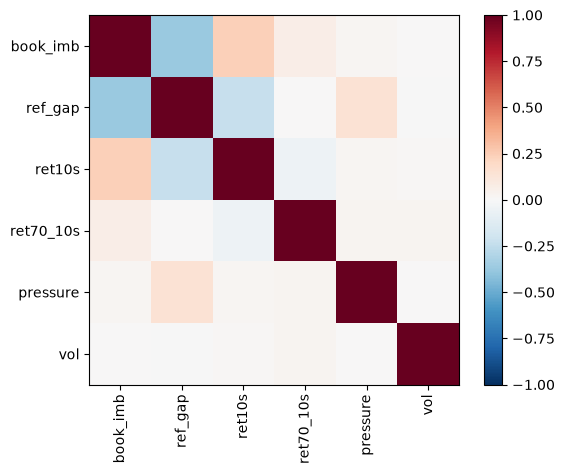

In [48]:
plt.imshow(correlation_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(correlation_matrix)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix)), correlation_matrix.columns)
plt.colorbar()

In [49]:
val = add_features(val)
pp([(i, evaluate(val, i, "target")) for i in cols])

[('book_imb',
  {'mean': np.float64(-0.11027020820712),
   'vol': np.float64(0.016257614155399596),
   't': np.float64(-45.49960635440761),
   'share': np.float64(0.0),
   'mae': np.float64(6.178215666405368)}),
 ('ref_gap',
  {'mean': np.float64(0.08341179495089335),
   'vol': np.float64(0.04741323658223011),
   't': np.float64(11.801416044145858),
   'share': np.float64(0.9555555555555556),
   'mae': np.float64(6.4790525311687865)}),
 ('ret10s',
  {'mean': np.float64(-0.06123131865372338),
   'vol': np.float64(0.027231406481893077),
   't': np.float64(-15.083766343767435),
   'share': np.float64(0.022222222222222223),
   'mae': np.float64(7.012775474741489)}),
 ('ret70_10s',
  {'mean': np.float64(-0.025895939524724104),
   'vol': np.float64(0.0494757642102737),
   't': np.float64(-3.5111179408411832),
   'share': np.float64(0.17777777777777778),
   'mae': np.float64(9.858783689114857)}),
 ('pressure',
  {'mean': np.float64(0.019709826529192287),
   'vol': np.float64(0.029214877143224

### Pressure, book imbalance, reference gap, past returns, and vol can be used, stronger signal is book imbalance that tends to fade

In [50]:
x_train = train[cols]
print(x_train.isna().sum())

book_imb          0
ref_gap           0
ret10s        77033
ret70_10s    539231
pressure          0
vol          462198
dtype: int64


In [51]:
mu, sd = train[cols].mean(), train[cols].std()
x_train = ((train[cols] - mu) / sd).fillna(0)
x_val   = ((val[cols]   - mu) / sd).fillna(0)

In [52]:
model = sm.OLS(train["target"], sm.add_constant(x_train)).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                 1.605e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        11:49:44   Log-Likelihood:            -1.5530e+07
No. Observations:             4236815   AIC:                         3.106e+07
Df Residuals:                 4236808   BIC:                         3.106e+07
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0484      0.005    -10.531      0.0

In [53]:
train = train.assign(predict_1 = model.predict(sm.add_constant(x_train)))
val = val.assign(predict_1 = model.predict(sm.add_constant(x_val)))

In [54]:
log_results("predict_1", "First model")
pp(results)

[{'name': 'Constant zero',
  'train_mean': nan,
  'train_vol': nan,
  'train_t': np.float64(nan),
  'train_share': nan,
  'train_mae': np.float64(6.496792541851205),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100963085430054)},
 {'name': 'Constant median',
  'train_mean': np.float64(1.2350263058163118e-18),
  'train_vol': np.float64(2.3740233735299764e-18),
  'train_t': np.float64(2.2071277448830675),
  'train_share': np.float64(0.6111111111111112),
  'train_mae': np.float64(6.496512608240876),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100917272940325)},
 {'name': 'First model',
  'train_mean': np.float64(0.15645100583803792),
  'train_vol': np.float64(0.04209164210747522),
  'train_t': np.float64(73.40316632065151),
  'train_share': np.float64(1.0),
  'train_mae': np.float64(6.417081089388444),
  'val_mean': np.float64(0.12311178812172044),
  'val_vo

In [55]:
idx = x_train.sample(300_000, random_state=0).index
qr = sm.QuantReg(train.loc[idx, "target"], sm.add_constant(x_train.loc[idx])).fit(q=0.5)
pred_val = qr.predict(sm.add_constant(x_val))
pred_train = qr.predict(sm.add_constant(x_train))

In [56]:
train = train.assign(predict_1MAE = pred_train)
val = val.assign(predict_1MAE = pred_val)

In [57]:
log_results("predict_1MAE", "First model MAE")
pp(results)

[{'name': 'Constant zero',
  'train_mean': nan,
  'train_vol': nan,
  'train_t': np.float64(nan),
  'train_share': nan,
  'train_mae': np.float64(6.496792541851205),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100963085430054)},
 {'name': 'Constant median',
  'train_mean': np.float64(1.2350263058163118e-18),
  'train_vol': np.float64(2.3740233735299764e-18),
  'train_t': np.float64(2.2071277448830675),
  'train_share': np.float64(0.6111111111111112),
  'train_mae': np.float64(6.496512608240876),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100917272940325)},
 {'name': 'First model',
  'train_mean': np.float64(0.15645100583803792),
  'train_vol': np.float64(0.04209164210747522),
  'train_t': np.float64(73.40316632065151),
  'train_share': np.float64(1.0),
  'train_mae': np.float64(6.417081089388444),
  'val_mean': np.float64(0.12311178812172044),
  'val_vo

In [58]:
evaluate(val, "target", "predict_1MAE")

{'mean': np.float64(0.12186423887099254),
 'vol': np.float64(0.03853211435398165),
 't': np.float64(21.215813877105884),
 'share': np.float64(0.9777777777777777),
 'mae': np.float64(6.058947276639839)}

In [59]:
print(val.predict_1MAE.median(), val.predict_1MAE.std())
print(val.target.median(), val.target.std())

-0.10461210688298574 1.3279597121005506
-0.039935112 9.020562526379576


In [60]:
x_train = x_train.clip(-5,5)
x_val = x_val.clip(-5,5)
qr = sm.QuantReg(train.loc[idx, "target"], sm.add_constant(x_train.loc[idx])).fit(q=0.5)
pred_val = qr.predict(sm.add_constant(x_val))
pred_train = qr.predict(sm.add_constant(x_train))

In [61]:
train = train.assign(predict_1MAE = pred_train)
val = val.assign(predict_1MAE = pred_val)

In [62]:
log_results("predict_1MAE", "First model MAE CLIPPED")
pp(results)

[{'name': 'Constant zero',
  'train_mean': nan,
  'train_vol': nan,
  'train_t': np.float64(nan),
  'train_share': nan,
  'train_mae': np.float64(6.496792541851205),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100963085430054)},
 {'name': 'Constant median',
  'train_mean': np.float64(1.2350263058163118e-18),
  'train_vol': np.float64(2.3740233735299764e-18),
  'train_t': np.float64(2.2071277448830675),
  'train_share': np.float64(0.6111111111111112),
  'train_mae': np.float64(6.496512608240876),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100917272940325)},
 {'name': 'First model',
  'train_mean': np.float64(0.15645100583803792),
  'train_vol': np.float64(0.04209164210747522),
  'train_t': np.float64(73.40316632065151),
  'train_share': np.float64(1.0),
  'train_mae': np.float64(6.417081089388444),
  'val_mean': np.float64(0.12311178812172044),
  'val_vo

In [63]:
# Models improvement on baseline validation:
ols_imp = (results[2]["val_mae"] - results[0]["val_mae"])/ results[0]["val_mae"]
mae_imp = (results[3]["val_mae"] - results[0]["val_mae"])/ results[0]["val_mae"]
mae_clip_imp = (results[4]["val_mae"] - results[0]["val_mae"])/ results[0]["val_mae"]
print(ols_imp, mae_imp, mae_clip_imp)

-0.00596384095426512 -0.006886750206791934 -0.008488766595020701


In [64]:
inner_tr = train[train["date_id"] <= 344]
inner_va = train[train["date_id"] > 344]

params = dict(objective="l1", learning_rate=0.05, n_jobs=os.cpu_count(), verbose=-1)
gbm = lgb.LGBMRegressor(n_estimators=1000, **params)
gbm.fit(inner_tr[cols], inner_tr["target"],
        eval_X=inner_va[cols], eval_y=inner_va["target"],
        callbacks=[lgb.early_stopping(50, verbose=False)])
n_trees = gbm.best_iteration_
print("trees chosen on days 345-389:", n_trees)

gbm = lgb.LGBMRegressor(n_estimators=n_trees, **params)
gbm.fit(train[cols], train["target"])

trees chosen on days 345-389: 329


,learning_rate,0.05
,n_estimators,329
,objective,'l1'
,n_jobs,20
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,class_weight,None
,min_split_gain,0.0


In [65]:
train = train.assign(pred_gbm=gbm.predict(train[cols]))
val = val.assign(pred_gbm=gbm.predict(val[cols]))
log_results("pred_gbm", "First Model GBM")
pp(results)

[{'name': 'Constant zero',
  'train_mean': nan,
  'train_vol': nan,
  'train_t': np.float64(nan),
  'train_share': nan,
  'train_mae': np.float64(6.496792541851205),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100963085430054)},
 {'name': 'Constant median',
  'train_mean': np.float64(1.2350263058163118e-18),
  'train_vol': np.float64(2.3740233735299764e-18),
  'train_t': np.float64(2.2071277448830675),
  'train_share': np.float64(0.6111111111111112),
  'train_mae': np.float64(6.496512608240876),
  'val_mean': nan,
  'val_vol': nan,
  'val_t': np.float64(nan),
  'val_share': nan,
  'val_mae': np.float64(6.100917272940325)},
 {'name': 'First model',
  'train_mean': np.float64(0.15645100583803792),
  'train_vol': np.float64(0.04209164210747522),
  'train_t': np.float64(73.40316632065151),
  'train_share': np.float64(1.0),
  'train_mae': np.float64(6.417081089388444),
  'val_mean': np.float64(0.12311178812172044),
  'val_vo

In [66]:
gbm_imp = (results[5]["val_mae"] - results[0]["val_mae"])/ results[0]["val_mae"]
print(gbm_imp)

-0.01377811249338486


### Comparing Lightgbm and OLS performances

In [67]:
err = val.assign(
    e_gbm=(val["target"] - val["pred_gbm"]).abs(),
    e_qr=(val["target"] - val["predict_1MAE"]).abs(),
)
daily = err.groupby("date_id")[["e_gbm", "e_qr"]].mean()
diff = daily["e_gbm"] - daily["e_qr"]

t = diff.mean() / (diff.std() / np.sqrt(len(diff)))
print(diff.mean(), t, (diff < 0).mean())

-0.03227010407199175 -16.744177540573244 1.0


In [68]:
print(pd.Series(gbm.booster_.feature_importance("gain"), index=cols).sort_values())

ret70_10s     28669.678472
vol           37917.236175
pressure      55480.672896
ret10s        71370.270577
ref_gap      235947.919826
book_imb     559425.079895
dtype: float64


Final model: LightGBM with an L1 objective on six features (book imbalance, reference gap, 10-second return, the return from t−70 s to t−10 s, auction pressure, volatility), with the number of trees chosen on the last 45 train days. It improves validation MAE by 1.4% over predicting zero

Main doubt: about 80% of LightGBM's gain comes from book imbalance and the reference gap, both partly mechanical effects of where wap sits in the spread, which may not survive trading costs.

In [69]:
val["pos"] = val["pred_gbm"] - val.groupby("time_id")["pred_gbm"].transform("mean")
tot = val["pos"].abs().groupby(val["time_id"]).transform("sum")
val["pos"] = val["pos"]/tot

In [70]:
v = val[val["seconds_in_bucket"] % 60 == 0]

In [71]:
v = v.assign(pnl=v["pos"] * v["target"])

In [72]:
pnl_day = v.groupby("date_id")["pnl"].sum()

<Axes: xlabel='date_id'>

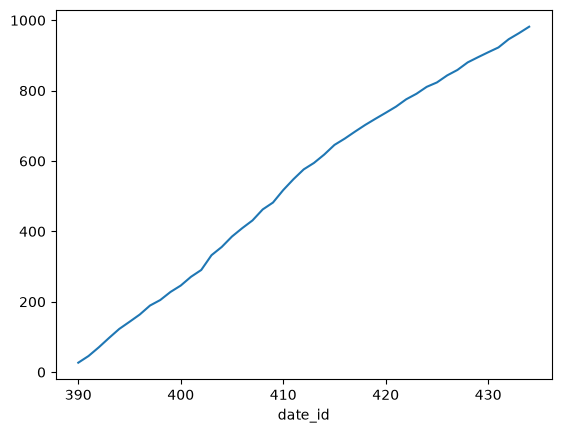

In [73]:
pnl_day.cumsum().plot()

In [74]:
mu, sig = pnl_day.mean(), pnl_day.std()
sharpe = mu/sig * np.sqrt(252)
print(mu, sig, sharpe)

21.816907291596394 5.958303151404601 58.12605663393458


### Strategy works well before the costs

**Cost model.** Positions are the LightGBM predictions demeaned across stocks at each snapshot and scaled to a gross exposure of 1, rebalanced every 60 s (the target horizon). Each rebalance is charged the full quoted spread on the absolute position, a rough proxy for crossing half the spread in and half out. The book is neutral to the equal-weight cross-section, not exactly to Optiver's synthetic index.

In [75]:
v = v.assign(cost=v["pos"].abs() * v["spread"], net=v["pnl"] - v["pos"].abs() * v["spread"])
net_pnl_day = v.groupby("date_id")["net"].sum()

<Axes: xlabel='date_id'>

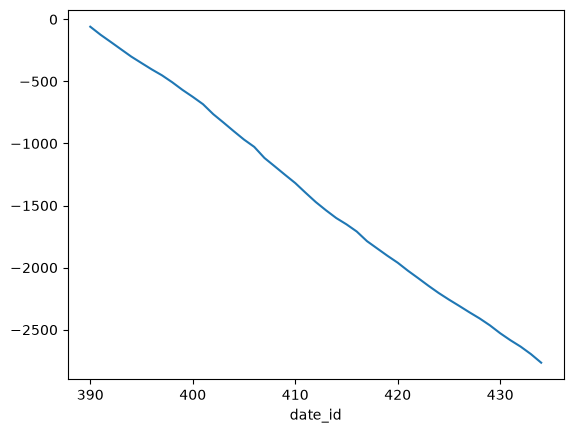

In [76]:
net_pnl_day.cumsum().plot()

### Signal is real but not tradable

# **Final check on the test set** (days 435–480, opened once)

Same features, same train-only scaling, same fitted models: nothing is refit here.

In [77]:
test = add_features(_test)
mu_x, sd_x = train[cols].mean(), train[cols].std()  # train-only scaling, as for validation
x_test = ((test[cols] - mu_x) / sd_x).fillna(0).clip(-5, 5)
test = test.assign(t_zeros=0,
                   predict_1MAE=qr.predict(sm.add_constant(x_test)),
                   pred_gbm=gbm.predict(test[cols]))

rows = [("Constant zero", "t_zeros"), ("Quantile regression (clipped)", "predict_1MAE"), ("LightGBM (L1)", "pred_gbm")]
with np.errstate(divide="ignore", invalid="ignore"):
    final = pd.DataFrame({name: evaluate(test, col, "target") for name, col in rows}).T
final["mae_vs_zero"] = final["mae"] / final.loc["Constant zero", "mae"] - 1
final

,mean,vol,t,share,mae,mae_vs_zero
Constant zero,NaN,NaN,NaN,NaN,5.962432,0.000000
Quantile regression (clipped),0.116533,0.034809,22.705844,0.978261,5.919584,-0.007186
LightGBM (L1),0.135260,0.033195,27.636293,1.000000,5.894443,-0.011403


       mean_bps_per_day  annualised_sharpe
gross         18.999429          61.752190
net          -58.051919         -98.541646


<Axes: xlabel='date_id', ylabel='cumulative bps'>

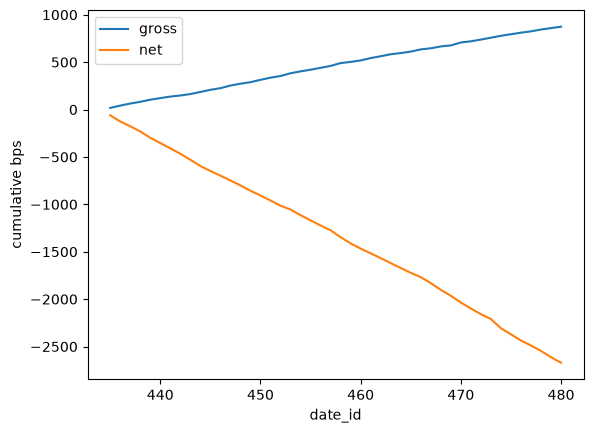

In [78]:
test["pos"] = test["pred_gbm"] - test.groupby("time_id")["pred_gbm"].transform("mean")
test["pos"] = test["pos"] / test["pos"].abs().groupby(test["time_id"]).transform("sum")
vt = test[test["seconds_in_bucket"] % 60 == 0]
vt = vt.assign(gross=vt["pos"] * vt["target"],
               net=vt["pos"] * vt["target"] - vt["pos"].abs() * vt["spread"])
daily_test = vt.groupby("date_id")[["gross", "net"]].sum()
print(pd.DataFrame({"mean_bps_per_day": daily_test.mean(),
                    "annualised_sharpe": daily_test.mean() / daily_test.std() * np.sqrt(252)}))
daily_test.cumsum().plot(ylabel="cumulative bps")

### **Test result**

On the 46 untouched test days, LightGBM cuts MAE by 1.1% against predicting zero (5.894 vs 5.962) and the clipped quantile regression by 0.7%, in line with validation (1.4% and 0.8%). LightGBM's daily IC is 0.135 (t = 27.6, positive on every test day).

The long-short book earns about 19 bps a day before costs and loses about 58 bps a day once the spread is paid: the signal is real and stable out of sample, but not tradable at a 60-second horizon under this cost model.